# 06 · Linear models: OLS, Ridge, Lasso, Elastic Net
Pipeline for every family: column selection → fold-wise imputation → centred interactions → wind one-hot → `StandardScaler` → linear model, all fitted inside each training fold.
Grids as specified (extended upward only when an optimum sits on the upper edge): Ridge α ∈ logspace(−3, 3, 13); Lasso α ∈ logspace(−4, 1, 10); Elastic Net α ∈ logspace(−4, 2, 10) × l1_ratio ∈ {0.1, 0.3, 0.5, 0.7, 0.9}.
Primary metric: MAE (mean over the same five folds).

**Choosing the final family from the data, not from the ranking.** Families within one standard error of the best CV-MAE are tied; among the tied families the properties of the *training design matrix*
decide: correlated groups **and** many weak predictors → Elastic Net; strong multicollinearity → Ridge; many weak predictors → Lasso; otherwise OLS.
A documented amendment (written after the training CV, before the freeze) skips a penalised family whose CV-optimal penalty sits at the no-shrinkage edge of its grid, because it is numerically OLS.
**Code.** `src/models.py` (`tune_family`, `select_final_model`), `src/statistics.py` (`data_properties`), `Experiment.stage_linear_models`.

In [1]:
import io, json, re, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
from src import config as C

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)

def table(stem, **kw):
    """results/tables/<stem>.csv (written by run_all.py)."""
    return pd.read_csv(C.TABLES / f"{stem}.csv", **kw)

def caption(stem):
    txt = (C.FIGURES / "figure_captions.md").read_text()
    m = re.search(rf"\*\*{re.escape(stem)}\*\* - (.*?)(?:\n\n|\Z)", txt, re.S)
    return m.group(1).strip() if m else ""

def fig(stem, width=1500):
    """Show results/figures/<stem>.png (down-scaled to keep the notebook small) with the caption computed from the data."""
    im = PILImage.open(C.FIGURES / f"{stem}.png")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue())); display(Markdown(f"*{caption(stem)}*"))

def log_grep(pattern, maxlen=420):
    """Print the lines of results/logs/run_all.log that match a regular expression."""
    for line in (C.LOGS / "run_all.log").read_text().splitlines():
        if re.search(pattern, line):
            print(line[:maxlen])

## 1. Cross-validated results and the selection outcome

In [2]:
display(table("table_S07_linear_models_cv_selection"))

,Model,selected hyper-parameters,CV MAE,CV RMSE,CV R²,non-zero coef.,within 1 SE of best,selected
0,OLS,-,10.62 ± 1.35,18.90 ± 2.77,0.9418 ± 0.0169,54/54,True,NaN
1,Ridge,"{""alpha"": 0.001}",10.62 ± 1.35,18.90 ± 2.77,0.9418 ± 0.0169,54/54,True,NaN
2,Lasso,"{""alpha"": 0.2154}",10.51 ± 1.29,19.00 ± 2.93,0.9414 ± 0.0160,29/54,True,★
3,ElasticNet,"{""alpha"": 0.0001, ""l1_ratio"": 0.9}",10.62 ± 1.35,18.90 ± 2.77,0.9418 ± 0.0169,54/54,True,NaN


## 2. Data properties of the training design that drive the choice

In [3]:
display(table("table_S08_training_design_properties").round(3))
log_grep(r"^DATA PROPERTIES|^   correlated group|^SELECTION|pre-registered rule alone")

,property,value
0,max VIF,376.65
1,features with VIF > 10,10.00
2,condition number,78.17
3,correlated groups (|r|>=0.8),3.00
4,weak predictors (|Spearman|<0.10),27.00
5,share weak,0.50


DATA PROPERTIES of the training design of Set C: max VIF 376.7 (PM25_roll_mean_3), 10 features > 10; condition number 78; 3 correlated groups (|r| >= 0.8); weak predictors 27/54 (50 %)
   correlated group: PM25_t, PM25_lag_1, PM25_lag_3, PM25_lag_6, PM25_lag_12, PM25_roll_mean_3, PM25_roll_mean_6, PM25_roll_mean_12 ...
   correlated group: TEMP, PRES
   correlated group: TEMP_x_hour_sin, DEWP_x_hour_sin
SELECTION: Best mean CV-MAE: Lasso (10.508); 1 SE = 0.577; families within 1 SE: ['OLS', 'Ridge', 'Lasso', 'ElasticNet']. Training-design properties: max VIF 376.7 (PM25_roll_mean_3), 10 features with VIF > 10; 3 correlated groups (|r| >= 0.8); 50.0% of features weak (|Spearman| < 0.1; threshold 50%). Implied family: ElasticNet (correlated groups of predictors AND many weak/redundant predictors -> feature selection t
  (pre-registered rule alone would have chosen ElasticNet; the amendment is recorded in results/logs/preregistration.json)


## 3. Pre-registered rule and recorded amendment

In [4]:
pre = json.loads((C.LOGS / "preregistration.json").read_text())
print(json.dumps(pre["model_selection_rule"], indent=2))
for a in pre.get("amendments", []):
    print("\nAMENDMENT:", json.dumps(a, indent=2))

{
  "metric": "mean CV-MAE (primary)",
  "tie_tolerance": "1.0 standard error of the best model's fold MAEs",
  "among_tied_families": "decided by the data properties of the TRAINING design matrix: correlated groups AND many weak predictors -> ElasticNet; strong multicollinearity -> Ridge; many weak predictors -> Lasso; else OLS",
  "thresholds": {
    "max_vif": 10.0,
    "cluster_abs_rho": 0.8,
    "min_clusters": 2,
    "weak_abs_spearman": 0.1,
    "weak_share": 0.5
  }
}

AMENDMENT: {
  "written_utc": "2026-10-04T19:09:10+00:00",
  "stage": "after training CV of the linear families, before the design freeze (test set locked)",
  "change": "a penalised family whose CV-optimal penalty is on the no-shrinkage edge of its grid is numerically OLS and is skipped in the property-implied preference list",
  "reason": "Best mean CV-MAE: Lasso (10.508); 1 SE = 0.577; families within 1 SE: ['OLS', 'Ridge', 'Lasso', 'ElasticNet']. Training-design properties: max VIF 376.7 (PM25_roll_mean_3), 1

## 4. Tuning curve of the selected family

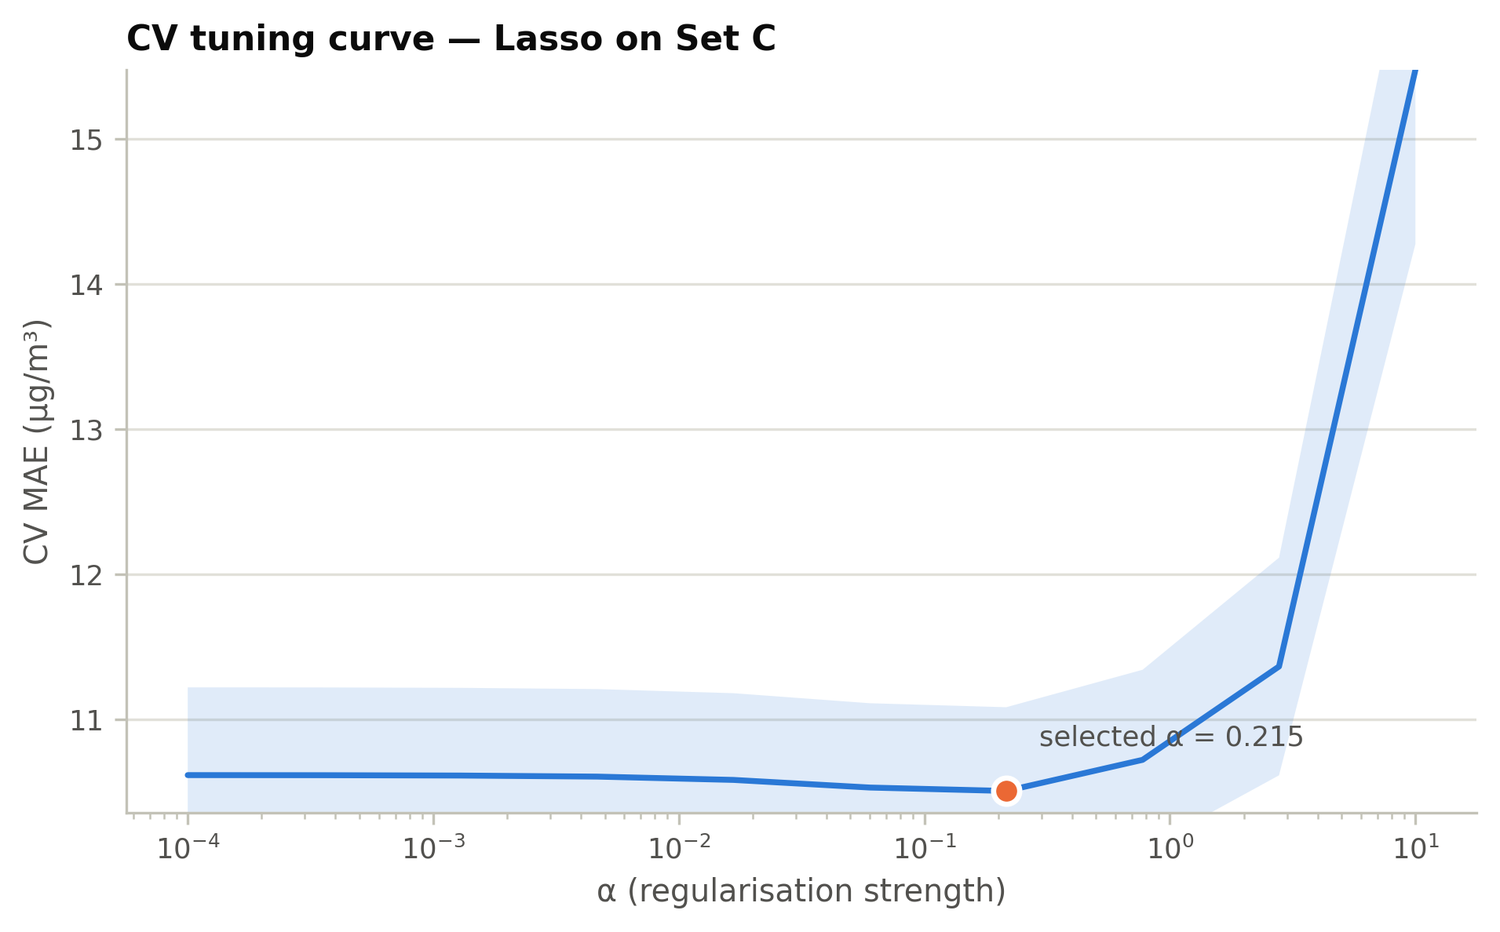

*Mean 5-fold time-series CV MAE of the selected family (Lasso) against the regularisation strength α (band: ±1 standard error). Orange: selected configuration (α = 0.215; 29 of 54 coefficients non-zero; CV-MAE 10.51 µg/m³). For every α up to the selected value the CV MAE is within 0.11 µg/m³ of the minimum; at the largest α of the grid (10) it is 15.48 µg/m³. For Ridge and ElasticNet the CV optimum lies on the no-shrinkage edge of the grid (table_S07): the penalty did not help, i.e. the fit is numerically OLS.*

final model: Lasso | feature set: C | hyper-parameters: {'alpha': 0.21544346900318845}


In [5]:
fig("figure_06_tuning_curve")
final = json.loads((C.MODELS / "selected_hyperparameters.json").read_text())["final_model"]
print("final model:", final["family"], "| feature set:", final["feature_set"], "| hyper-parameters:", final["hyperparameters"])